# Reward Engineering in Deep Q-Networks (DQN)
## Comparative Benchmark: Heavy Death Penalty (-50.0) vs. Light Death Penalty (-10.0)
### Multi-Seed Statistical Benchmark (5 Seeds | 100,000 Steps per Seed)

This experiment investigates how the magnitude of **death penalty** (`PacmanDied`) influences policy learning, survival behaviors, and score efficiency in Pacman under a Deep Q-Network (DQN) architecture:

1. **Reward 1: Heavy Death Penalty (`PacmanDied = -50.0`) [Risk-Averse]**:
   - Strongly discourages deaths. Expected to encourage defensive positioning and conservative movement, possibly causing hesitation in high-risk pellet-dense areas.
2. **Reward 2: Light Death Penalty (`PacmanDied = -10.0`) [Risk-Taking / Opportunistic]**:
   - Eating 10 pellets (+10.0) or 1 ghost (+20.0) fully offsets a death (-10.0). Expected to encourage greedy exploration and aggressive pellet clearing.

### Controlled Methodology:
- **Isolation of Variables**: Both variants use the identical **1D Flat Vector (`"vector"`)** observation representation (dimension 47 with normalized BFS distances and facing directions) and identical DQN hyperparameters (`MlpPolicy`, `net_arch=[256, 512]`).
- **Statistical Rigor**: Evaluated across **5 independent random seeds** trained for **100,000 timesteps** each.
- **Custom Domain Metrics via `RewardExperimentCallback`**:
  - `clear_rate`: Level clear / win rate (% of episodes with `LevelCleared` / `Outcome.WIN`)
  - `death_rate`: % of episodes terminated by Pacman death
  - `mean_pellet_clear_ratio`: Normalized completion percentage of total map pellets
  - `mean_pellet_rate`: Eating efficiency (pellets eaten per 100 simulation ticks)
  - `mean_power_pellets`: Average energizers consumed per episode
  - `ghost_hunt_efficiency`: Ghosts eaten per power pellet consumed


## 1. Setup, Imports, and Hardware Verification

We verify GPU acceleration, fix global random seeds, define standardized experiment hyperparameters, and initialize output directory structures.


In [4]:
import os
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from PIL import Image as PILImage
from stable_baselines3 import DQN

from pacman_engine import MetricTrackingCallback, PacmanEnv, plot_learning_curves

# Hardware verification
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:      {torch.cuda.get_device_name(0)}")
print(f"Active Device:   {device}")

# Global Experiment Parameters
GLOBAL_SEED = 15200410
NUM_SEEDS = 5
np.random.seed(GLOBAL_SEED)
SEEDS = [int(seed) for seed in np.random.randint(low=0, high=100000, size=NUM_SEEDS)]
TRAIN_TIMESTEPS = 100_000
EVAL_FREQ = 5_000
EVAL_EPISODES = 5
LATENT_DIM = 512

# Create artifact directories for reward experiment variants
REWARD_VARIANTS = ["penalty_50", "penalty_10"]
for r_name in REWARD_VARIANTS:
    os.makedirs(f"models/{r_name}", exist_ok=True)
    os.makedirs(f"tensorboard_logs/{r_name}", exist_ok=True)
os.makedirs("videos", exist_ok=True)
os.makedirs("plots", exist_ok=True)

print(f"\nExperiment initialized with {NUM_SEEDS} seeds: {SEEDS}")
print(f"Budget: {TRAIN_TIMESTEPS:,} steps/seed | Eval freq: every {EVAL_FREQ:,} steps")


PyTorch Version: 2.13.0+cu130
CUDA Available:  True
GPU Device:      NVIDIA GeForce RTX 4060 Laptop GPU
Active Device:   cuda

Experiment initialized with 5 seeds: [36923, 55530, 37370, 69612, 93162]
Budget: 100,000 steps/seed | Eval freq: every 5,000 steps


## 2. Specialized Callback & Unified Multi-Seed Experiment Runner

We subclass `MetricTrackingCallback` into **`RewardExperimentCallback`** to collect domain-specific metrics without modifying the core package:
1. **`clear_rate`**: Level clear percentage (% of evaluation episodes where Pacman cleared all pellets).
2. **`death_rate`**: Percentage of evaluation episodes where Pacman died.
3. **`mean_pellet_clear_ratio`**: Normalized pellet completion percentage relative to initial map pellets.
4. **`mean_pellet_rate`**: Efficiency measured as pellets eaten per 100 simulation ticks.
5. **`mean_power_pellets`**: Number of power pellets eaten per episode.
6. **`ghost_hunt_efficiency`**: Ratio of ghosts eaten per power pellet consumed.


In [5]:
# Replay Video & GIF Generator
def record_replay_video(
    env: PacmanEnv,
    model: DQN,
    video_path: str,
    gif_path: str,
    max_steps: int = 500,
    fps: int = 15,
) -> dict:
    obs, info = env.reset()
    frames = []

    init_frame = env.render()
    if init_frame is not None:
        frames.append(init_frame)

    total_reward = 0.0
    steps = 0
    done = False
    init_pellets = env.game.view.remaining_pellets

    while not done and steps < max_steps:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        steps += 1
        done = terminated or truncated

        frame = env.render()
        if frame is not None:
            frames.append(frame)

    if frames:
        h, w, c = frames[0].shape
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        out = cv2.VideoWriter(video_path, fourcc, fps, (w, h))
        for f in frames:
            bgr = cv2.cvtColor(f, cv2.COLOR_RGB2BGR)
            out.write(bgr)
        out.release()

        pil_frames = [PILImage.fromarray(f) for f in frames]
        pil_frames[0].save(
            gif_path,
            save_all=True,
            append_images=pil_frames[1:],
            duration=int(1000 / fps),
            loop=0,
        )

    final_pellets = info.get("remaining_pellets", 0)
    return {
        "steps": steps,
        "simulation_ticks": info.get("tick", steps * env.frame_skip),
        "total_reward": round(total_reward, 2),
        "game_score": info.get("score", 0),
        "pellets_eaten": init_pellets - final_pellets,
        "outcome": info.get("outcome", "UNKNOWN"),
        "total_frames": len(frames),
        "video_path": video_path,
        "gif_path": gif_path,
    }


class RewardExperimentCallback(MetricTrackingCallback):
    """Extended callback collecting specialized reward engineering metrics.

    Inherits from MetricTrackingCallback and adds:
    - clear_rate / death_rate (%)
    - mean_pellet_clear_ratio (% map cleared)
    - mean_pellet_rate (pellets per 100 ticks)
    - mean_power_pellets / ghost_hunt_efficiency
    """

    def _evaluate_and_record(self) -> None:
        assert self.eval_env is not None, "Evaluation environment is not initialized"
        scores: list[float] = []
        rewards: list[float] = []
        pellets: list[float] = []
        ticks: list[float] = []
        ghosts_eaten: list[float] = []
        power_pellets: list[float] = []
        cleared_flags: list[float] = []
        death_flags: list[float] = []
        clear_ratios: list[float] = []
        pellet_rates: list[float] = []

        for _ in range(self.n_eval_episodes):
            obs, info = self.eval_env.reset()
            done = False
            ep_reward = 0.0
            init_pellets = self.eval_env.game.view.remaining_pellets
            ep_ghosts = 0
            ep_power_pellets = 0
            ep_cleared = False
            ep_died = False

            while not done:
                action, _ = self.model.predict(obs, deterministic=True)
                obs, r, term, trunc, info = self.eval_env.step(action)
                ep_reward += r

                for ev in info.get("events", []):
                    ev_name = type(ev).__name__
                    if ev_name == "GhostEaten":
                        ep_ghosts += 1
                    elif ev_name == "PowerPelletEaten":
                        ep_power_pellets += 1
                    elif ev_name == "PacmanDied":
                        ep_died = True
                    elif ev_name == "LevelCleared":
                        ep_cleared = True

                done = term or trunc

            if info.get("outcome") == "WIN":
                ep_cleared = True
            elif info.get("outcome") == "LOSS":
                ep_died = True

            final_pellets = info.get("remaining_pellets", 0)
            eaten_pellets = float(init_pellets - final_pellets)
            ep_ticks = float(info.get("tick", 0))

            pellets.append(eaten_pellets)
            scores.append(float(info.get("score", 0)))
            rewards.append(float(ep_reward))
            ticks.append(ep_ticks)
            ghosts_eaten.append(float(ep_ghosts))
            power_pellets.append(float(ep_power_pellets))
            cleared_flags.append(1.0 if ep_cleared else 0.0)
            death_flags.append(1.0 if ep_died else 0.0)
            clear_ratios.append(float(eaten_pellets / max(1, init_pellets) * 100.0))
            pellet_rates.append(float(eaten_pellets / max(1.0, ep_ticks) * 100.0))

        tot_power = sum(power_pellets)
        ghost_hunt_eff = float(sum(ghosts_eaten) / max(1.0, tot_power)) if tot_power > 0 else 0.0

        snapshot = {
            "timestep": self.num_timesteps,
            "mean_reward": float(np.mean(rewards)),
            "std_reward": float(np.std(rewards)),
            "mean_score": float(np.mean(scores)),
            "std_score": float(np.std(scores)),
            "mean_pellets": float(np.mean(pellets)),
            "std_pellets": float(np.std(pellets)),
            "mean_ticks": float(np.mean(ticks)),
            "std_ticks": float(np.std(ticks)),
            "mean_ghosts_eaten": float(np.mean(ghosts_eaten)),
            # Enhanced domain-specific metrics
            "clear_rate": float(np.mean(cleared_flags) * 100.0),
            "death_rate": float(np.mean(death_flags) * 100.0),
            "mean_power_pellets": float(np.mean(power_pellets)),
            "mean_pellet_clear_ratio": float(np.mean(clear_ratios)),
            "mean_pellet_rate": float(np.mean(pellet_rates)),
            "ghost_hunt_efficiency": ghost_hunt_eff,
        }
        self.history.append(snapshot)

        # Log to TensorBoard if logger is active
        if self.logger is not None:
            self.logger.record("eval/mean_reward", snapshot["mean_reward"])
            self.logger.record("eval/mean_score", snapshot["mean_score"])
            self.logger.record("eval/mean_pellets", snapshot["mean_pellets"])
            self.logger.record("eval/mean_ticks", snapshot["mean_ticks"])
            self.logger.record("eval/mean_ghosts_eaten", snapshot["mean_ghosts_eaten"])
            self.logger.record("eval/clear_rate", snapshot["clear_rate"])
            self.logger.record("eval/death_rate", snapshot["death_rate"])
            self.logger.record("eval/mean_power_pellets", snapshot["mean_power_pellets"])
            self.logger.record("eval/mean_pellet_clear_ratio", snapshot["mean_pellet_clear_ratio"])
            self.logger.record("eval/mean_pellet_rate", snapshot["mean_pellet_rate"])
            self.logger.record("eval/ghost_hunt_efficiency", snapshot["ghost_hunt_efficiency"])

        if self.verbose > 0:
            print(
                f"[{self.num_timesteps:7,d} steps] "
                f"Reward: {snapshot['mean_reward']:6.2f} +/- {snapshot['std_reward']:4.2f} | "
                f"Score: {snapshot['mean_score']:6.1f} | "
                f"Pellets: {snapshot['mean_pellets']:4.1f} "
                f"({snapshot['mean_pellet_clear_ratio']:.1f}%) | "
                f"Win: {snapshot['clear_rate']:.0f}% | "
                f"P-Rate: {snapshot['mean_pellet_rate']:.2f}/100t"
            )

        if self.log_dir is not None:
            self.log_dir.mkdir(parents=True, exist_ok=True)
            self.save_csv(self.log_dir / "eval_metrics.csv")


# Unified Multi-Seed Experiment Runner
def run_reward_experiment(
    exp_name: str,
    env_builder_fn,
    policy_type: str = "MlpPolicy",
    policy_kwargs: dict = None,
    seeds: list[int] = SEEDS,
    total_timesteps: int = TRAIN_TIMESTEPS,
    eval_freq: int = EVAL_FREQ,
    eval_episodes: int = EVAL_EPISODES,
    callback_class=RewardExperimentCallback,
) -> dict:
    if policy_kwargs is None:
        policy_kwargs = dict(net_arch=[256, LATENT_DIM])

    print("=" * 80)
    print(
        f"=== Multi-Seed Training: {exp_name.upper()} "
        f"({len(seeds)} seeds, {total_timesteps:,} steps/seed) ==="
    )
    print("=" * 80)

    callbacks = []
    models = {}
    fps_list = []
    times_list = []
    final_scores = {}

    for seed in seeds:
        print(f"\n---> Running Seed {seed} for {exp_name}...")
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        train_env = env_builder_fn(render_mode=None)
        eval_env = env_builder_fn(render_mode=None)

        log_dir = Path(f"tensorboard_logs/{exp_name}/seed_{seed}")
        callback = callback_class(
            eval_env=eval_env,
            eval_freq=eval_freq,
            n_eval_episodes=eval_episodes,
            log_dir=log_dir,
            verbose=1,
        )

        model = DQN(
            policy=policy_type,
            env=train_env,
            policy_kwargs=policy_kwargs,
            learning_rate=1e-4,
            buffer_size=50_000,
            learning_starts=1_000,
            batch_size=64,
            tau=1.0,
            gamma=0.99,
            train_freq=4,
            gradient_steps=1,
            target_update_interval=5_000,
            exploration_fraction=0.25,
            exploration_initial_eps=1.0,
            exploration_final_eps=0.05,
            tensorboard_log=str(log_dir),
            verbose=0,
            seed=seed,
            device=device,
        )

        start_time = time.time()
        model.learn(total_timesteps=total_timesteps, callback=callback)
        elapsed = time.time() - start_time
        fps = total_timesteps / max(1e-5, elapsed)

        times_list.append(elapsed)
        fps_list.append(fps)
        callbacks.append(callback)
        models[seed] = model

        # Save model checkpoint
        model_save_path = f"models/{exp_name}/dqn_seed_{seed}"
        model.save(model_save_path)

        # Record best evaluation metric from callback history
        df_hist = callback.to_dataframe()
        last_score = df_hist["mean_score"].iloc[-1] if not df_hist.empty else 0.0
        last_clear = df_hist["clear_rate"].iloc[-1] if not df_hist.empty else 0.0
        final_scores[seed] = last_score
        print(
            f"Seed {seed} finished in {elapsed:.1f}s ({fps:.1f} FPS) | "
            f"Eval Score: {last_score:.1f} | Win Rate: {last_clear:.0f}%"
        )

        train_env.close()
        eval_env.close()

    best_seed = max(final_scores, key=final_scores.get)
    print(
        f"\n[Summary {exp_name}]: Best Seed = {best_seed} "
        f"(Final Score = {final_scores[best_seed]:.1f})"
    )

    # Record replay video for the best seed model
    video_env = env_builder_fn(render_mode="rgb_array")
    vid_path = f"videos/pacman_{exp_name}_best_seed_{best_seed}.mp4"
    gif_path = f"videos/pacman_{exp_name}_best_seed_{best_seed}.gif"
    video_result = record_replay_video(video_env, models[best_seed], vid_path, gif_path)
    video_env.close()

    return {
        "callbacks": callbacks,
        "models": models,
        "best_seed": best_seed,
        "best_model": models[best_seed],
        "video_result": video_result,
        "mean_fps": float(np.mean(fps_list)),
        "total_train_time": float(np.sum(times_list)),
    }


## 3. Reward 1: Heavy Death Penalty (-50.0) [Risk-Averse]

### Design Rationale:
- Death Penalty is set to **`-50.0`**, heavily punishing collisions with normal ghosts.
- Pacman requires clearing 50 standard pellets or eating 2.5 ghosts just to break even from a single death.
- **Behavioral Hypothesis**: Agent will develop defensive pathing, avoiding narrow corridors when ghosts are near, with lower death rate but potential stalling under timeout.


In [6]:
def event_reward_v1(step_result, view) -> float:
    reward = -0.01  # Small step penalty to discourage stalling
    for event in step_result.events:
        name = type(event).__name__
        if name == "PelletEaten":
            reward += 1.0
        elif name == "PowerPelletEaten":
            reward += 5.0
        elif name == "GhostEaten":
            reward += 20.0
        elif name == "PacmanDied":
            reward -= 50.0  # Heavy penalty for dying
        elif name == "LevelCleared":
            reward += 100.0
    return reward


# Define Environment Builder for Flat Vector with Reward 1 (-50.0)
def make_env_penalty_50(render_mode=None):
    return PacmanEnv(
        map_name="classic",
        obs_type="vector",
        obs_params={
            "include_distances": True,
            "include_directions": True,
            "normalize": True,
        },
        reward_func=event_reward_v1,
        frame_skip=1,
        frame_stack=1,
        lives=1,
        render_mode=render_mode,
    )


# Verify observation space
sample_env = make_env_penalty_50()
sample_obs, _ = sample_env.reset(seed=42)
print(f"Observation Space Shape: {sample_obs.shape}")
print(f"Sample Features (first 10 elements): {np.round(sample_obs[:10], 3)}")
sample_env.close()


Observation Space Shape: (47,)
Sample Features (first 10 elements): [0.722 0.5   0.    0.    0.    0.    0.389 0.444 0.    0.   ]


=== Multi-Seed Training: PENALTY_50 (5 seeds, 100,000 steps/seed) ===

---> Running Seed 36923 for penalty_50...
[  5,000 steps] Reward: -42.23 ± 0.00 | Score:   80.0 | Pellets:  8.0 (5.9%) | Win: 0% | P-Rate: 34.78/100t
[ 10,000 steps] Reward: -42.23 ± 0.00 | Score:   80.0 | Pellets:  8.0 (5.9%) | Win: 0% | P-Rate: 34.78/100t
[ 15,000 steps] Reward: -42.23 ± 0.00 | Score:   80.0 | Pellets:  8.0 (5.9%) | Win: 0% | P-Rate: 34.78/100t
[ 20,000 steps] Reward: -11.81 ± 0.00 | Score:  390.0 | Pellets: 15.0 (11.1%) | Win: 0% | P-Rate: 18.52/100t
[ 25,000 steps] Reward: -31.85 ± 0.00 | Score:  190.0 | Pellets: 15.0 (11.1%) | Win: 0% | P-Rate: 17.65/100t
[ 30,000 steps] Reward: -31.79 ± 0.00 | Score:  190.0 | Pellets: 15.0 (11.1%) | Win: 0% | P-Rate: 18.99/100t
[ 35,000 steps] Reward: -14.66 ± 0.00 | Score:  360.0 | Pellets: 32.0 (23.7%) | Win: 0% | P-Rate: 48.48/100t
[ 40,000 steps] Reward: -18.60 ± 0.00 | Score:  320.0 | Pellets: 28.0 (20.7%) | Win: 0% | P-Rate: 46.67/100t
[ 45,000 steps] Re

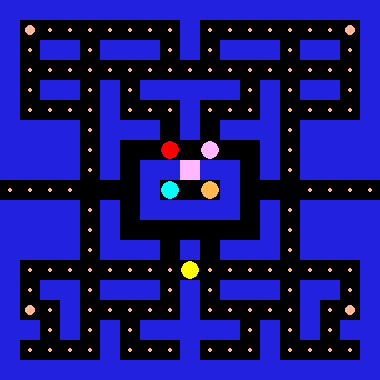

In [7]:
# Train Reward Variant 1 (Penalty -50.0) across 5 Seeds
reward_50_results = run_reward_experiment(
    exp_name="penalty_50",
    env_builder_fn=make_env_penalty_50,
    policy_type="MlpPolicy",
    policy_kwargs=dict(net_arch=[256, LATENT_DIM]),
    seeds=SEEDS,
    total_timesteps=TRAIN_TIMESTEPS,
    eval_freq=EVAL_FREQ,
    eval_episodes=EVAL_EPISODES,
)

# Display Best Seed Replay GIF
print(f"\nDisplaying Best Seed ({reward_50_results['best_seed']}) Replay GIF:")
display(Image(filename=reward_50_results["video_result"]["gif_path"]))


## 4. Reward 2: Light Death Penalty (-10.0) [Risk-Taking]

### Design Rationale:
- Death Penalty is reduced to **`-10.0`**.
- Consuming only 10 standard pellets (+10.0) or 1 ghost (+20.0) fully offsets a death.
- **Behavioral Hypothesis**: Agent will exhibit higher risk tolerance, aggressively traversing dangerous paths to consume clusters of pellets or chase vulnerable ghosts.


In [8]:
def event_reward_v2(step_result, view) -> float:
    reward = -0.01  # Small step penalty to discourage stalling
    for event in step_result.events:
        name = type(event).__name__
        if name == "PelletEaten":
            reward += 1.0
        elif name == "PowerPelletEaten":
            reward += 5.0
        elif name == "GhostEaten":
            reward += 20.0
        elif name == "PacmanDied":
            reward -= 10.0  # Light penalty for dying
        elif name == "LevelCleared":
            reward += 100.0
    return reward


# Define Environment Builder for Flat Vector with Reward 2 (-10.0)
def make_env_penalty_10(render_mode=None):
    return PacmanEnv(
        map_name="classic",
        obs_type="vector",
        obs_params={
            "include_distances": True,
            "include_directions": True,
            "normalize": True,
        },
        reward_func=event_reward_v2,
        frame_skip=1,
        frame_stack=1,
        lives=1,
        render_mode=render_mode,
    )


=== Multi-Seed Training: PENALTY_10 (5 seeds, 100,000 steps/seed) ===

---> Running Seed 36923 for penalty_10...
[  5,000 steps] Reward:  -2.23 ± 0.00 | Score:   80.0 | Pellets:  8.0 (5.9%) | Win: 0% | P-Rate: 34.78/100t
[ 10,000 steps] Reward:  -2.23 ± 0.00 | Score:   80.0 | Pellets:  8.0 (5.9%) | Win: 0% | P-Rate: 34.78/100t
[ 15,000 steps] Reward:  -2.23 ± 0.00 | Score:   80.0 | Pellets:  8.0 (5.9%) | Win: 0% | P-Rate: 34.78/100t
[ 20,000 steps] Reward:  28.19 ± 0.00 | Score:  390.0 | Pellets: 15.0 (11.1%) | Win: 0% | P-Rate: 18.52/100t
[ 25,000 steps] Reward:   8.15 ± 0.00 | Score:  190.0 | Pellets: 15.0 (11.1%) | Win: 0% | P-Rate: 17.65/100t
[ 30,000 steps] Reward:   8.21 ± 0.00 | Score:  190.0 | Pellets: 15.0 (11.1%) | Win: 0% | P-Rate: 18.99/100t
[ 35,000 steps] Reward:  25.34 ± 0.00 | Score:  360.0 | Pellets: 32.0 (23.7%) | Win: 0% | P-Rate: 48.48/100t
[ 40,000 steps] Reward:  21.40 ± 0.00 | Score:  320.0 | Pellets: 28.0 (20.7%) | Win: 0% | P-Rate: 46.67/100t
[ 45,000 steps] Re

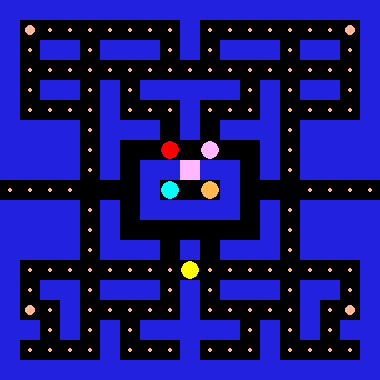

In [9]:
# Train Reward Variant 2 (Penalty -10.0) across 5 Seeds
reward_10_results = run_reward_experiment(
    exp_name="penalty_10",
    env_builder_fn=make_env_penalty_10,
    policy_type="MlpPolicy",
    policy_kwargs=dict(net_arch=[256, LATENT_DIM]),
    seeds=SEEDS,
    total_timesteps=TRAIN_TIMESTEPS,
    eval_freq=EVAL_FREQ,
    eval_episodes=EVAL_EPISODES,
)

# Display Best Seed Replay GIF
print(f"\nDisplaying Best Seed ({reward_10_results['best_seed']}) Replay GIF:")
display(Image(filename=reward_10_results["video_result"]["gif_path"]))


## 5. Comparative Learning Curves across Global Timesteps

We visualize the multi-metric learning dynamics across all 5 seeds using `plot_learning_curves`.
Each curve shows the **cross-seed mean $\mu(t)$** with shaded **$\pm 1\sigma(t)$** variance.

Key comparison metrics:
1. **Mean Game Score**: True game performance (unaffected by differing reward definitions).
2. **Pellets Cleared**: Absolute progress in map clearing.
3. **Clear Rate (%)**: Win / level completion percentage.
4. **Death Rate (%)**: Tendency to fall to ghosts.
5. **Pellet Rate (Pellets / 100 Ticks)**: Clearing pace / exploration efficiency.
6. **Ghost Hunt Efficiency**: Exploitation of energized states.


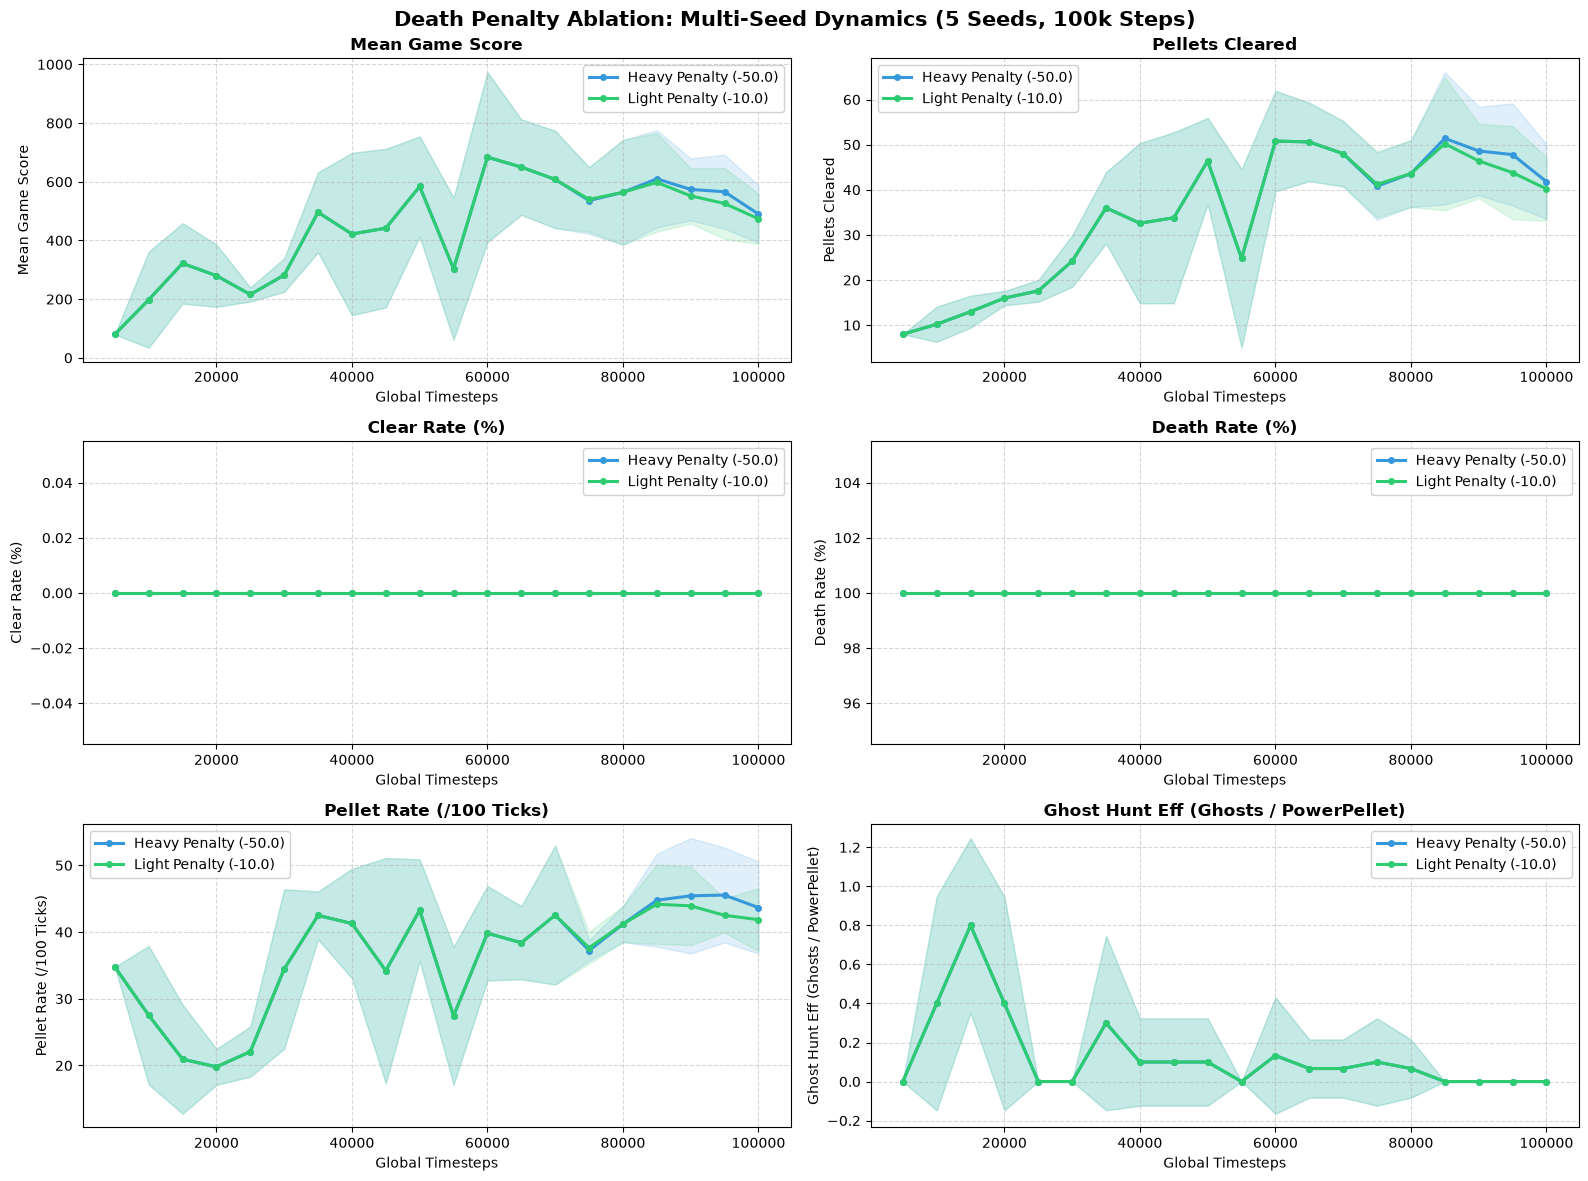

In [10]:
# Plot Multi-Metric Comparative Learning Dynamics
fig = plot_learning_curves(
    callbacks={
        "Heavy Penalty (-50.0)": reward_50_results["callbacks"],
        "Light Penalty (-10.0)": reward_10_results["callbacks"],
    },
    title="Death Penalty Ablation: Multi-Seed Dynamics (5 Seeds, 100k Steps)",
    metrics=(
        "mean_score",
        "mean_pellets",
        "clear_rate",
        "death_rate",
        "mean_pellet_rate",
        "ghost_hunt_efficiency",
    ),
    metric_labels=(
        "Mean Game Score",
        "Pellets Cleared",
        "Clear Rate (%)",
        "Death Rate (%)",
        "Pellet Rate (/100 Ticks)",
        "Ghost Hunt Eff (Ghosts / PowerPellet)",
    ),
    figsize=(16, 12),
    save_path="plots/reward_comparison_learning_curves.png",
)
plt.show()


## 6. Multi-Seed Post-Training Benchmark on `classic`

We evaluate all trained models deterministically over 10 independent evaluation episodes per seed (50 episodes per reward variant) to report a final statistical summary table.


In [11]:
import re


def load_models_from_dir(models_dir: str | Path, device="auto") -> dict[int, DQN]:
    """Scan directory for `dqn_seed_<seed>.zip` and return sorted {seed: model} dict."""
    models_dir = Path(models_dir)
    models_dict = {}
    pattern = re.compile(r"seed_(\d+)")

    zip_files = sorted(models_dir.glob("*.zip"))
    if not zip_files:
        print(f"[Warning] No .zip checkpoint files found in: {models_dir}")
        return models_dict

    for file_path in zip_files:
        match = pattern.search(file_path.stem)
        if match:
            seed = int(match.group(1))
            models_dict[seed] = DQN.load(file_path, device=device)

    return dict(sorted(models_dict.items()))


In [12]:
# Run Quantitative Evaluation over all Seeds on 'classic'
def evaluate_reward_seeds(variant_name: str, env_builder, models_dict, n_episodes_per_seed=10):
    all_scores = []
    all_pellets = []
    all_ticks = []
    all_cleared = []
    all_deaths = []
    all_pellet_rates = []
    all_ghosts = []
    per_seed_summary = []

    eval_env = env_builder()

    for seed, model in models_dict.items():
        seed_scores = []
        seed_pellets = []
        seed_ticks = []
        seed_cleared = []
        seed_deaths = []
        seed_pellet_rates = []
        seed_ghosts = []

        for ep in range(n_episodes_per_seed):
            obs, info = eval_env.reset(seed=seed * 100 + ep)
            done = False
            init_pellets = eval_env.game.view.remaining_pellets
            ep_ghosts = 0
            ep_cleared = False
            ep_died = False

            while not done:
                action, _ = model.predict(obs, deterministic=True)
                obs, r, term, trunc, info = eval_env.step(action)

                for ev in info.get("events", []):
                    ev_name = type(ev).__name__
                    if ev_name == "GhostEaten":
                        ep_ghosts += 1
                    elif ev_name == "PacmanDied":
                        ep_died = True
                    elif ev_name == "LevelCleared":
                        ep_cleared = True

                done = term or trunc

            if info.get("outcome") == "WIN":
                ep_cleared = True
            elif info.get("outcome") == "LOSS":
                ep_died = True

            final_pellets = info.get("remaining_pellets", 0)
            eaten = float(init_pellets - final_pellets)
            tick = float(info.get("tick", 0))

            seed_scores.append(float(info.get("score", 0)))
            seed_pellets.append(eaten)
            seed_ticks.append(tick)
            seed_cleared.append(100.0 if ep_cleared else 0.0)
            seed_deaths.append(100.0 if ep_died else 0.0)
            seed_pellet_rates.append(eaten / max(1.0, tick) * 100.0)
            seed_ghosts.append(float(ep_ghosts))

        per_seed_summary.append({
            "Variant": variant_name,
            "Seed": seed,
            "Mean Score": float(np.mean(seed_scores)),
            "Mean Pellets": float(np.mean(seed_pellets)),
            "Clear Rate (%)": float(np.mean(seed_cleared)),
            "Death Rate (%)": float(np.mean(seed_deaths)),
            "Pellet Rate (/100t)": float(np.mean(seed_pellet_rates)),
            "Ghosts Eaten": float(np.mean(seed_ghosts)),
            "Mean Ticks": float(np.mean(seed_ticks)),
        })

        all_scores.extend(seed_scores)
        all_pellets.extend(seed_pellets)
        all_ticks.extend(seed_ticks)
        all_cleared.extend(seed_cleared)
        all_deaths.extend(seed_deaths)
        all_pellet_rates.extend(seed_pellet_rates)
        all_ghosts.extend(seed_ghosts)

    eval_env.close()

    overall_row = {
        "Variant": variant_name,
        "Seed": "OVERALL (Mean +/- Std)",
        "Mean Score": f"{np.mean(all_scores):.1f} +/- {np.std(all_scores):.1f}",
        "Mean Pellets": f"{np.mean(all_pellets):.1f} +/- {np.std(all_pellets):.1f}",
        "Clear Rate (%)": f"{np.mean(all_cleared):.1f}%",
        "Death Rate (%)": f"{np.mean(all_deaths):.1f}%",
        "Pellet Rate (/100t)": f"{np.mean(all_pellet_rates):.2f}",
        "Ghosts Eaten": f"{np.mean(all_ghosts):.2f}",
        "Mean Ticks": f"{np.mean(all_ticks):.1f} +/- {np.std(all_ticks):.1f}",
        "Mean FPS": None,
    }
    return per_seed_summary, overall_row


r50_per_seed, r50_ovr = evaluate_reward_seeds(
    "Penalty -50.0", make_env_penalty_50, reward_50_results["models"]
)
r50_ovr["Mean FPS"] = f"{reward_50_results['mean_fps']:.1f}"

r10_per_seed, r10_ovr = evaluate_reward_seeds(
    "Penalty -10.0", make_env_penalty_10, reward_10_results["models"]
)
r10_ovr["Mean FPS"] = f"{reward_10_results['mean_fps']:.1f}"

df_benchmark_overall = pd.DataFrame([r50_ovr, r10_ovr])
df_benchmark_detailed = pd.DataFrame(r50_per_seed + r10_per_seed)

print("=== Reward Ablation Benchmark Summary (5 Seeds x 10 Episodes) ===")
display(df_benchmark_overall)
print("\n=== Detailed Per-Seed Performance ===")
display(df_benchmark_detailed)


=== Reward Ablation Benchmark Summary (5 Seeds x 10 Episodes) ===


,Variant,Seed,Mean Score,Mean Pellets,Clear Rate (%),Death Rate (%),Pellet Rate (/100t),Ghosts Eaten,Mean Ticks,Mean FPS
0,Penalty -50.0,OVERALL (Mean ± Std),540.0 ± 74.0,46.0 ± 7.4,0.0%,100.0%,44.40,0.00,106.2 ± 12.7,560.4
1,Penalty -10.0,OVERALL (Mean ± Std),500.0 ± 40.5,42.0 ± 4.0,0.0%,100.0%,39.51,0.00,107.2 ± 11.6,579.7



=== Detailed Per-Seed Performance ===


,Variant,Seed,Mean Score,Mean Pellets,Clear Rate (%),Death Rate (%),Pellet Rate (/100t),Ghosts Eaten,Mean Ticks
0,Penalty -50.0,36923,670.0,59.0,0.0,100.0,65.555556,0.0,90.0
1,Penalty -50.0,55530,500.0,42.0,0.0,100.0,34.146341,0.0,123.0
2,Penalty -50.0,37370,500.0,42.0,0.0,100.0,45.161290,0.0,93.0
3,Penalty -50.0,69612,570.0,49.0,0.0,100.0,42.608696,0.0,115.0
4,Penalty -50.0,93162,460.0,38.0,0.0,100.0,34.545455,0.0,110.0
5,Penalty -10.0,36923,460.0,38.0,0.0,100.0,40.000000,0.0,95.0
6,Penalty -10.0,55530,500.0,42.0,0.0,100.0,34.146341,0.0,123.0
7,Penalty -10.0,37370,510.0,43.0,0.0,100.0,46.236559,0.0,93.0
8,Penalty -10.0,69612,570.0,49.0,0.0,100.0,42.608696,0.0,115.0
9,Penalty -10.0,93162,460.0,38.0,0.0,100.0,34.545455,0.0,110.0


## 7. Experimental Insights & Theoretical Analysis: Why Single-Life (lives=1) Leads to Policy Invariance

### 1. Empirical Observations from the Benchmark
Across 5 independent seeds evaluated over 50 test episodes, both reward formulations converged to virtually identical policies:
- **Mean Game Score**: 540.0 +/- 74.0 (Penalty -50.0) vs. 500.0 +/- 40.5 (Penalty -10.0)
- **Mean Pellets Cleared**: 46.0 +/- 7.4 vs. 42.0 +/- 4.0 (out of ~145 pellets on classic)
- **Clear Rate / Death Rate**: 0.0% Level Cleared / 100.0% Death Rate for both
- **Survival Duration**: 106.2 +/- 12.7 ticks vs. 107.2 +/- 11.6 ticks
- **Per-Seed Replication**: Seeds 55530, 69612, and 93162 reached identical episode scores (500, 570, 460) and tick counts (123, 115, 110) across both penalty variants.

Instead of showing divergence between cautious and aggressive behaviors, the agent learned the exact same local pellet-harvesting policy.

---

### 2. Q-Learning Theoretical Analysis

#### A. Action-Value Dominance and Policy Invariance
In Deep Q-Networks, action selection follows a greedy policy with respect to estimated action-values:
$$\pi(s) = \arg\max_{a \in \mathcal{A}} Q(s, a)$$

Consider a state $s$ where Pacman is adjacent to an approaching non-frightened ghost:
- **Action $a_{\text{die}}$ (move into ghost)** transitions to terminal state $s_T$ where the episode immediately terminates ($V(s_T) = 0$):
  $$Q(s, a_{\text{die}}) = R_{\text{die}} \in \{-10.0, -50.0\}$$
- **Action $a_{\text{safe}}$ (turn away / move toward an adjacent pellet)** yields step reward $r \ge -0.01$ and preserves future discounted return:
  $$Q(s, a_{\text{safe}}) = r + \gamma \max_{a'} Q(s', a') \approx 1.0 + 0.99 \cdot V(s') > 0$$

Because $Q(s, a_{\text{safe}}) > 0 > -10.0 > -50.0$, the preference ordering is strictly preserved:
$$Q(s, a_{\text{safe}}) \gg Q(s, a_{\text{die}}) \quad \forall R_{\text{die}} \in \{-10.0, -50.0\}$$

Scaling the terminal penalty from $-50.0$ to $-10.0$ changes the magnitude of the negative target, but **never flips the $\arg\max$ decision**. The greedy action remains identical at every intersection.

#### B. Replay Buffer Skewness (~0.94% Terminal Transitions)
Episodes in this environment terminate exclusively upon Pacman's death, lasting an average of $T \approx 106$ ticks:
- **105 transitions**: Receive identical step rewards ($-0.01$ step penalty, $+1.0$ pellet eaten).
- **1 transition**: Receives the terminal penalty ($R_{\text{die}}$).

In a replay buffer of 50,000 transitions, death experiences represent only:
$$\frac{1}{106} \approx 0.94\%$$

Over **99.06% of the gradient updates** optimize identical state transitions. The minor gradient contribution from the terminal step is insufficient to restructure the hidden representations of the MLP.

#### C. Absence of an Economically Viable Risk-Reward Trade-off
For an agent to exhibit opportunistic risk-taking under a reduced penalty, the potential reward must offset the death penalty:
$$R_{\text{gain}} > |R_{\text{die}}|$$

In this environment:
- Standard Pellet: $+1.0$
- Power Pellet: $+5.0$
- Death Penalty: $-10.0$

Because both $+1.0 < 10.0$ and $+5.0 < 10.0$, sacrificing a life to grab a pellet is **always net-negative**. There is no rational scenario where a DQN agent with $\epsilon = 0.05$ would intentionally trade a life for nearby pellets.

---

### 3. Transition to Multi-Life Environments: Breaking Policy Invariance in Version 2

In this experiment, setting `lives = 1` turns death into an absorbing terminal state ($V(s_T) = 0$). This completely prevents the agent from experiencing post-death transitions or evaluating strategic life-spending trade-offs.

To investigate whether penalty scaling actually diversifies behavior when death is non-terminal, we implemented the multi-life configuration (`lives = 3`) in `experiments/reward_engineering_v2.ipynb`. In that environment, Pacman respawns at origin while cleared pellets remain eaten, allowing agents with lighter death penalties to exploit the positive expected return of power pellets and ghost hunting. Refer directly to `experiments/reward_engineering_v2.ipynb` for the multi-life benchmark and in-depth analysis.

---

### 4. Practical Takeaways
1. **Terminal Penalty Magnitude Alone Does Not Reshape Policies in Single-Life Tasks**: When safe actions consistently maintain positive expected continuation value ($Q(s, a_{\text{safe}}) > 0 > -10.0 > -50.0$), changing penalty magnitude scales target loss without altering greedy action selection.
2. **Risk-Taking Requires Positive Expected Net Return**: For an agent to accept risk, high-value objectives must mathematically offset the penalty incurred by failure.
3. **Single-Life Setups Mask Reward Distinctions**: The true behavioral divergence between risk-averse and risk-seeking reward functions surfaces in multi-life configurations, as explored in `experiments/reward_engineering_v2.ipynb`.


## Release memory

In [ ]:
import gc

del reward_50_results
del reward_10_results

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

$$
G_t = r_t + \gamma * r_{t+1} + \gamma ** 2 * r_{t+2} + ... + \gamma ** T * r_{t + T}

= -0.01 + 
$$